# 00 · Overview and decision map

**Purpose:** orient a reader: the task, the pipeline, where each decision lives, how to run it, and what was original.  
**Decisions implemented:** all of D1 to D8 (this notebook is the index) and the reproducibility claim of D5.  
**Inputs → outputs:** `dataset/`, `outputs/`, `cache/` → tables, one diagram and a replay proof; nothing is written.

*Run from the project root or from `notebooks/`; nothing is written, and no model is called (replay mode).*

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from ti import nbhelpers as nb
nb.setup()
print("replay mode: no network, no API key, no spend")

replay mode: no network, no API key, no spend


## 1. The task

*Transcript Intelligence* turns recorded calls (support, external, internal) into things different stakeholders can act on.
The brief asks for three pieces of analysis and three deliverables:

- **Task 1:** categorise the calls by theme with a pipeline, and explain why that approach.
- **Task 2:** sentiment across call types, with trends and **what they mean**, not only charts.
- **Task 3:** what else can be seen, for different stakeholders.
- **Deliverables:** a slide deck, this reference repo, and a short video demo.

The panel states what it grades: *thinking, judgment and the quality of insights*, not whether every line was hand-written.
So this repo is organised around **decisions and evidence**: every choice is in `DECISIONS.md` with its reasons, the rejected
alternatives and the known weakness, and each notebook below shows the evidence for one stage.

## 2. Where each part of the brief is answered

| Brief | Answered in |
|---|---|
| Task 1: categories, approach, examples per category | `02_stage1_categories` |
| Task 2: sentiment across call types | `03_stage2_sentiment` (how it is measured), `04_trends_and_meaning` (what it means) |
| Task 3: further insights | `05_bonus_insights` |
| "Why this approach", reasoning, limits | `01_stage0_call_type`, `02`, `06_model_choice_and_limits`, and `DECISIONS.md` |
| Readable code | `src/ti/` (one module per stage), small helpers in `src/ti/nbhelpers.py` |
| Disclosure of what is original or generated | section 7 below |

## 3. The pipeline

The three LLM stages read the transcript only. The upstream summary, topics and score shipped in the dataset are kept in a separate `Provided` object and are comparison baselines, never inputs (`Meeting.view_for(stage)` is the only door).

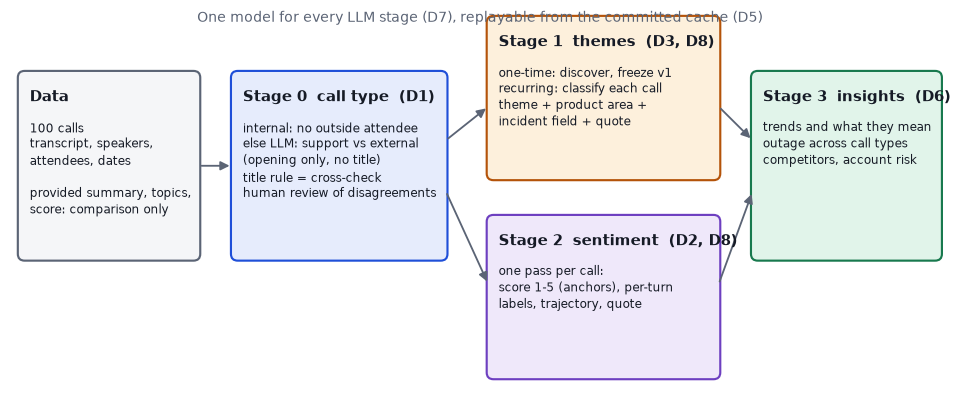

In [2]:
fig = nb.pipeline_diagram()
plt.show()

## 4. The data

In [3]:
from ti.load import load_meetings
ms = load_meetings()
c = nb.calls()
facts = {
    "meetings": len(ms),
    "JSON files read": len(list((ROOT / "dataset").glob("*/*.json"))),
    "transcript sentences": sum(len(m.turns) for m in ms),
    "words": sum(len(t.sentence.split()) for m in ms for t in m.turns),
    "median call length (minutes)": round(float(np.median([m.duration_min for m in ms])), 1),
    "first / last call": f"{c.date.min()} / {c.date.max()}",
    "calls with a customer present": int(sum(not m.is_internal_by_metadata for m in ms)),
    "distinct customer accounts": int(c.loc[c.account != "", "account"].nunique()),
}
nb.table(pd.DataFrame({"value": facts}).reset_index(names="fact"))

fact,value
meetings,100
JSON files read,600
transcript sentences,4313
words,141357
median call length (minutes),29.6
first / last call,2026-02-03 / 2026-04-28
calls with a customer present,70
distinct customer accounts,32


The dataset has **no field for call type**. Stage 0 (notebook 01) assigns it. The result of that stage, used everywhere after it:

In [4]:
nb.table(c.type.value_counts().rename_axis("call type (Stage 0)").reset_index(name="calls"))

call type (Stage 0),calls
external,40
support,30
internal,30


## 5. Decision map

Every row links a decision in `DECISIONS.md` to the code and the notebook that shows its evidence. `B2` is the list of eight
criteria (stable over time, owned and actionable, evidence-linked, no hidden upstream dependence, validation that scales,
one method over time, defined for every call, few moving parts) that every option was judged against.

| Decision | What was decided | Implemented in | Notebook |
|---|---|---|---|
| D1 | Stage 0 call type: certain from metadata when no customer; an LLM reads the opening (title withheld) for support vs external; the title rule is an independent cross-check; a human reviews disagreements | `src/ti/stage0.py`, `prompts/stage0_v1.md` | 01 |
| D2, D2a | Sentiment: one structured LLM pass per call, whole-call score for all calls plus customer-side score, written anchors, validation against the upstream labels and a small hand-check by the candidate | `src/ti/stage2.py`, `prompts/stage2_v1.md` | 03 |
| D3, D3a | Themes: discover once, freeze a versioned taxonomy, classify every call against it; transcript input; theme plus product area; at most two tags | `src/ti/stage1.py`, `src/ti/stage1_discovery.py`, `prompts/stage1_v1.md` | 02 |
| D4 | No synthetic data | none was generated | 00 (section 7) |
| D5 | Stack and repo: Python 3.12 with `uv`, OpenRouter, a committed cache that makes every result replayable | `src/ti/llm.py`, `cache/`, `pyproject.toml` | 00, 06 |
| D6 | Three connected bonus insights (competitors, outage blast radius, account risk list) plus one described idea | `src/ti/analysis/candidates.py` | 05 |
| D7 | One model for every stage, provider pinned; the pre-written decision rule was overridden | `.env.example`, `eval/bakeoff.py`, `docs/bakeoff-report.md` | 06 |
| D8 | Taxonomy v1 and anchors v1 frozen under the candidate's delegation | `outputs/stage1/taxonomy_v1.json`, `prompts/stage2_v1.md` | 02, 03 |

## 6. Reproducibility proof

A temperature of 0 does **not** guarantee identical output from these models (measured in notebook 06). What makes the results
reproducible is the **committed cache of raw model responses**: each stage is re-run below in *replay* mode, which reads only
the cache (a cache miss would raise an error, never call the network), and the result is compared with the stored output.

In [5]:
proof = pd.DataFrame([nb.replay_check(s) for s in (0, 1, 2)])
proof["stage"] = ["call type", "themes", "sentiment"]
proof["identical to stored output"] = proof.mismatches.eq(0)
nb.table(proof[["stage", "calls", "llm_calls", "served_from_cache", "mismatches", "identical to stored output"]])

stage,calls,llm_calls,served_from_cache,mismatches,identical to stored output
call type,100,70,70,0,True
themes,100,100,100,0,True
sentiment,100,100,100,0,True


## 7. How to run, and what is original

**Replay (no key, no network, no cost):** `uv sync`, then open any notebook or run `uv run pytest`. This is what the notebooks do.
**Live (to create new cache entries):** `cp .env.example .env`, add an `OPENROUTER_API_KEY`, set `TI_MODE=live`, and run
`PYTHONPATH=src uv run python -m ti.stage1` (and `ti.stage2`). A changed prompt, model or setting changes the cache key, so it
re-runs the affected stage for all calls (decision criterion 6).

In [6]:
n_ill = nb.prompt_body("stage2_v1").count("Illustrative example")
nb.md(f"""
**Disclosures**

- **AI assistance.** Claude Code (Claude Sonnet 5.5) wrote and ran much of the code and analysis under the candidate's
  direction, with subagents for build and analysis tasks and the main session verifying their output. The three LLM stages of the
  pipeline itself run on `google/gemini-3.8-flash` through OpenRouter (D7). The assignment permits AI tools.
- **Delegation (D8).** The taxonomy v1 and the anchors v1 were finalised by the assistant under the candidate's delegation, from
  an LLM-proposed draft. The candidate's own validation is a hand-check of their own review (small samples; they cannot confirm they stayed blind to the model answers; status in notebooks 02 and 03).
- **Data.** The {len(ms)} meetings are used exactly as provided: the loader only reads `dataset/`. **No synthetic data was
  generated** (D4). The only invented text in the repo's prompts is {n_ill} short *illustrative* mini-excerpts inside
  `prompts/stage2_v1.md`, labelled as such, to show the output format.
- **What the evidence can and cannot support.** {len(ms)} calls from one fictional company that look synthetic, and no outcome
  labels: trends are directional, and agreement with the dataset's own AI-written labels is *consistency*, not accuracy.
""")


**Disclosures**

- **AI assistance.** Claude Code (Claude Sonnet 5.5) wrote and ran much of the code and analysis under the candidate's
  direction, with subagents for build and analysis tasks and the main session verifying their output. The three LLM stages of the
  pipeline itself run on `google/gemini-3.8-flash` through OpenRouter (D7). The assignment permits AI tools.
- **Delegation (D8).** The taxonomy v1 and the anchors v1 were finalised by the assistant under the candidate's delegation, from
  an LLM-proposed draft. The candidate's own validation is a hand-check of their own review (small samples; they cannot confirm they stayed blind to the model answers; status in notebooks 02 and 03).
- **Data.** The 100 meetings are used exactly as provided: the loader only reads `dataset/`. **No synthetic data was
  generated** (D4). The only invented text in the repo's prompts is 2 short *illustrative* mini-excerpts inside
  `prompts/stage2_v1.md`, labelled as such, to show the output format.
- **What the evidence can and cannot support.** 100 calls from one fictional company that look synthetic, and no outcome
  labels: trends are directional, and agreement with the dataset's own AI-written labels is *consistency*, not accuracy.
